# 1 — Risk differentiation : discrétisation des variables (segment SB)

Ce notebook construit le découpage final de chaque variable candidate du segment SB (mono-détenus avec engagement), conformément au chapitre 4 du cours : découpage fin, regroupement de modalités, contrôle de la monotonie, de la stabilité temporelle et du pouvoir discriminant (WOE / IV).

Les paramètres du regroupement sont fixés une fois pour toutes :

| Paramètre | Valeur | Justification |
|---|---|---|
| `n_bins` | 20 | découpage fin de départ (classes de 5 %) |
| `part_min` | 5 % | effectif minimal d'une classe, pour la robustesse des taux |
| `defauts_min` | 20 | nombre minimal de défauts par classe |
| `ecart_min` | 30 % | écart relatif de risque minimal entre classes adjacentes (4.6) |


In [1]:
# Cellule 1 — paramètres
from pathlib import Path
import matplotlib.pyplot as plt
import polars as pl
from utils import binning, exploration
from utils.segmentation import split_train_test

pl.Config.set_tbl_rows(-1); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_hide_column_data_types(True)

ID, TARGET, DATE, SEGMENT = "gdt", "ddefaut_ndb", "datdelhis", "segment"
BASE = Path("data/processed/base_segmentee.parquet")
SEGMENT_ETUDIE = "SB_mono_avec_eng"
CODE = SEGMENT_ETUDIE.split("_")[0]
PARAMS = dict(n_bins=20, part_min=0.05, defauts_min=20, ecart_min=0.3)   # SM : defauts_min=10, part_min=0.08
NON_MONOTONES = ()          # variables à relation en U justifiée métier
SEUIL_CRAMER = 0.7          # redondance entre variables découpées (3.2)

## 1.1 Variables candidates

On part des 54 variables au statut « candidate » à l'issue des statistiques descriptives (notebook 0b) : variables non constantes, peu manquantes, discriminantes (IV ≥ 0,02) et non redondantes (|Spearman| < 0,8).

**Valeurs aberrantes et impossibles (2.3).** Les valeurs extrêmes repérées au notebook 0b ne sont pas écrêtées : le binning les place dans la classe extrême de leur variable, avec les autres grandes valeurs, et elles n'exercent donc aucun effet de levier sur le modèle. En revanche, les valeurs impossibles par définition (ancienneté négative, âge supérieur à 110 ans, ancienneté de la relation supérieure à l'âge du client, part hors de [0 ; 1]) sont considérées comme des erreurs et passées en valeur manquante, traitée comme une modalité à part entière au binning ; elles ne concernent que 5 dossiers. Cas particulier : 432 dossiers ont une ancienneté saine de −1 à −3 jours, c'est-à-dire un retour à l'état sain juste après la date d'observation. Leur taux de défaut (6,7 %, cinq fois la moyenne du segment) montre que la valeur est informative : elle est ramenée à 0 (« vient de redevenir sain ») plutôt que neutralisée. Cette valeur s'appuie sur une date postérieure de quelques jours à la date d'observation, ce qui constitue une fuite d'information minime ; l'alternative stricte serait d'exclure ces dossiers du périmètre, mais leur taux de défaut, très inférieur à celui des dossiers en défaut à date (72 %), les rapproche plutôt de clients en période probatoire. Certaines valeurs monétaires très extrêmes (soldes de plusieurs centaines de millions) sont signalées mais conservées, faute de pouvoir établir sans dictionnaire détaillé s'il s'agit d'erreurs ou d'une unité différente (centimes, cumuls).

Trois étapes de feature engineering (2.4) complètent ou remplacent ensuite certaines variables.

**Défaut passé.** Les six variables `Dfo_max_*` indiquent un défaut passé sur des fenêtres successives (M-4 à M-36). Chacune ne concerne qu'environ 0,3 % de la population, trop peu pour former une classe stable. Elles sont fusionnées en un indicateur unique `Dfo_max_Mm4_Mm36` (défaut passé dans les trois dernières années, maximum des six fenêtres), ce qui supprime aussi une redondance évidente. *54 → 49 variables.*

**Historique d'arriérés.** Les huit fenêtres `NBJ_ARR_SS_max_*` (pire arriéré sur M-1/M-3 … M-37/M-48) décrivent le même phénomène à des horizons différents et sont liées entre elles. Elles sont remplacées par quatre variables de synthèse, plus interprétables :
- `NB_FENETRES_ARR` : nombre de fenêtres avec arriéré (récurrence) ;
- `NBJ_ARR_MAX_12M` et `NBJ_ARR_MAX_13_48M` : gravité récente et ancienne ;
- `ARR_TENDANCE` : aucun arriéré / ancien seulement / récent seulement / récurrent.

Une fenêtre manquante (historique indisponible) n'est pas assimilée à une absence d'arriéré. Ces synthèses sont nettement plus discriminantes que les fenêtres prises isolément (IV test de 0,97 pour `ARR_TENDANCE` contre 0,72 au mieux pour une fenêtre). Les variables d'arriéré à date (`NBJ_ARR_SS`, `ARR_GDT`), qui décrivent la situation actuelle et non l'historique, sont conservées à côté. *49 → 45 variables.*

**Utilisation du découvert.** `TX_UTIL_DAV` rapporte le solde débiteur moyen (`solde_debiteur`) à l'autorisation de découvert (`engagement_DAV`) ; 0 = compte non débiteur. Un débit sans autorisation reçoit une valeur extrême conventionnelle, qui le place dans la classe la plus risquée. Les ordres de grandeur suggèrent que les deux variables ne sont pas exprimées dans la même unité (solde vraisemblablement en centimes) : le ratio n'est donc pas directement un pourcentage d'utilisation, mais il lui reste proportionnel. Le binning ne dépendant que de l'ordre des valeurs, les classes et le pouvoir discriminant n'en sont pas affectés. C'est un risk driver classique du scoring comportemental : il mesure la tension de trésorerie relativement aux moyens accordés, ce que le solde débiteur seul ne permet pas. *45 → 46 variables.*

**Bilan du feature engineering (2.4).** Les trois familles de variables du cours sont représentées :
- *ratios métier* : taux d'utilisation du découvert `TX_UTIL_DAV`, dont la base nulle (absence d'autorisation) est traitée par une catégorie dédiée, ainsi que les ratios fournis dans la base (`RATIO_SOLDE_MOYEN_SUR_EPARGNE`, `RATIO_ECR`, `PART_EPARGNE_DANS_AVOIRS`…). Le taux d'endettement n'a pas pu être construit : la base ne contient ni revenu ni charges de crédit mensuelles ;
- *variables de tendance* : pentes et évolutions du solde fournies dans la base (`SOLDE_PENTE_*`, `SOLDE_EVOLUTION_*`), complétées par la tendance des arriérés `ARR_TENDANCE` ;
- *agrégats temporels glissants* : nombre de fenêtres avec arriéré, pire arriéré sur 12 mois et sur 13 à 48 mois, indicateur de défaut passé sur 3 ans.

Toutes les variables construites agrègent des fenêtres antérieures à la date d'observation (M-1 à M-48) : elles respectent la contrainte de fenêtre d'observation (1.2) et n'introduisent pas de fuite d'information.

**Modalités rares à risque fort (4.5).** Certaines variables ont une modalité rare mais très risquée (arriérés, défaut passé, incident Banque de France). Exemple : `NBJ_ARR_SS > 0` concerne 1,6 % de la population avec 20 % de défaut, contre 0,9 % pour le reste. Avec le seuil général de 5 %, cette modalité serait fusionnée avec les sains et l'information perdue. Pour ces 8 variables, l'effectif minimal d'une classe est abaissé à 0,5 % : `NBJ_ARR_SS`, `NB_FENETRES_ARR`, `NBJ_ARR_MAX_12M`, `NBJ_ARR_MAX_13_48M`, `ARR_TENDANCE`, `Dfo_max_Mm4_Mm36`, `CODITDBDF_PAR` et `CAUSE_SAIN_M0`. Le critère de 20 défauts minimum et la règle de stabilité mensuelle restent appliqués : une classe rare n'est conservée que si elle est stable.

In [2]:
# Cellule 2 — segment, variables candidates (0b), valeurs impossibles et feature engineering
base = pl.read_parquet(BASE).filter(pl.col(SEGMENT) == SEGMENT_ETUDIE)
base = base.with_columns(pl.col("CODACVPRO_modif").cast(pl.Int64).cast(pl.String))
fiche = pl.read_excel(f"outputs/stat_desc_{CODE}.xlsx", sheet_name=f"{CODE}_Fiche_variables")
VARS = fiche.filter(pl.col("statut").str.starts_with("candidate"))["variable"].to_list()
print(len(VARS), "variables candidates")

# 2.3 : valeurs impossibles par définition -> missing (les extrêmes plausibles sont laissés au binning)
VALEURS_IMPOSSIBLES = {
    "AGE_PP_EN_MOIS": pl.col("AGE_PP_EN_MOIS") > 110 * 12,
    "ANCIENNETE_modif": pl.col("ANCIENNETE_modif") > pl.col("AGE_PP_EN_MOIS"),
    "PART_EPARGNE_DANS_AVOIRS": ~pl.col("PART_EPARGNE_DANS_AVOIRS").is_between(0, 1),
}
impossibles, _ = exploration.controle_groupes(
    base, {**VALEURS_IMPOSSIBLES, "anciennete_jour_sain_M0 < 0": pl.col("anciennete_jour_sain_M0") < 0}, TARGET)
print(impossibles)
base = exploration.neutraliser_valeurs(base, VALEURS_IMPOSSIBLES)

# 2.3 : ancienneté saine négative (1 à 3 jours) = retour à l'état sain juste après la date d'observation
# -> ramenée à 0 ("vient de redevenir sain") plutôt que neutralisée : valeur informative (≈ 6,7 % de défaut)
base = base.with_columns(pl.col("anciennete_jour_sain_M0").clip(lower_bound=0))

# 2.4 : les 6 fenêtres Dfo_max_* (défaut passé, ~0,3 % chacune) fusionnées en un indicateur sur 3 ans
DFO = [v for v in VARS if v.startswith("Dfo_max")]
base = base.with_columns(Dfo_max_Mm4_Mm36=pl.max_horizontal(DFO))
VARS = [v for v in VARS if v not in DFO] + ["Dfo_max_Mm4_Mm36"]

# 2.4 : synthèse de l'historique d'arriérés ; les synthèses remplacent les 8 fenêtres NBJ_ARR_SS_max_*
base = exploration.variables_arrieres(base)
ARR_CONSTRUITES = ["NB_FENETRES_ARR", "NBJ_ARR_MAX_12M", "NBJ_ARR_MAX_13_48M", "ARR_TENDANCE"]
FENETRES_ARR = [v for v in VARS if v.startswith("NBJ_ARR_SS_max")]
VARS = [v for v in VARS if v not in FENETRES_ARR] + ARR_CONSTRUITES

# 2.4 : taux d'utilisation du découvert autorisé
base = exploration.taux_utilisation_decouvert(base)
VARS = VARS + ["TX_UTIL_DAV"]

# 4.5 : modalités rares à risque fort -> classe gardée dès 0,5 % de la population si ≥ defauts_min défauts
RARES = [v for v in VARS if v.startswith(("NBJ_ARR", "Dfo_max"))
         or v in ("CODITDBDF_PAR", "CAUSE_SAIN_M0", "NB_FENETRES_ARR", "ARR_TENDANCE")]
PARAMS_VARIABLES = {v: {"part_min": 0.005} for v in RARES}
print(len(VARS), "variables |", len(RARES), "à modalité rare :", RARES)

54 variables candidates
shape: (4, 4)
┌─────────────────────────────┬─────┬──────────┬─────────────┐
│ groupe                      ┆ n   ┆ n_defaut ┆ taux_defaut │
╞═════════════════════════════╪═════╪══════════╪═════════════╡
│ AGE_PP_EN_MOIS              ┆ 2   ┆ 0.0      ┆ 0.0         │
│ ANCIENNETE_modif            ┆ 0   ┆ 0.0      ┆ null        │
│ PART_EPARGNE_DANS_AVOIRS    ┆ 3   ┆ 0.0      ┆ 0.0         │
│ anciennete_jour_sain_M0 < 0 ┆ 432 ┆ 29.0     ┆ 0.06713     │
└─────────────────────────────┴─────┴──────────┴─────────────┘
46 variables | 8 à modalité rare : ['NBJ_ARR_SS', 'CAUSE_SAIN_M0', 'CODITDBDF_PAR', 'Dfo_max_Mm4_Mm36', 'NB_FENETRES_ARR', 'NBJ_ARR_MAX_12M', 'NBJ_ARR_MAX_13_48M', 'ARR_TENDANCE']


## 1.2 Échantillons d'apprentissage et de test

La base compte une ligne par client et par mois d'observation ; environ 2 % des clients sont observés sur plusieurs mois. Elle est découpée en 70 % apprentissage / 30 % test :
- le tirage se fait **par client** (`gdt`) : toutes les observations d'un même client vont dans le même échantillon. Sinon, le test contiendrait des clients déjà vus à l'apprentissage et le Gini serait surestimé ;
- il est **stratifié** sur le défaut et le mois d'observation, pour que les deux échantillons aient la même structure de risque dans le temps.

Les découpages sont construits sur l'apprentissage uniquement ; le test sert à vérifier qu'ils se généralisent. L'échantillon Out-of-Time sera fourni ultérieurement et servira à une validation finale.

Le tableau ci-dessous montre des taux de défaut identiques entre échantillons et entre mois (≈ 1,2 %), et aucun client n'est présent dans les deux échantillons.

In [3]:
# Cellule 3 — granularité : une ligne par client et par mois d'observation
print(base.select(
    n_lignes=pl.len(),
    n_clients=pl.col(ID).n_unique(),
    n_client_dates=pl.struct([ID, DATE]).n_unique(),
))

shape: (1, 3)
┌──────────┬───────────┬────────────────┐
│ n_lignes ┆ n_clients ┆ n_client_dates │
╞══════════╪═══════════╪════════════════╡
│ 126625   ┆ 123867    ┆ 126625         │
└──────────┴───────────┴────────────────┘


In [4]:
# Cellule 4 — découpage apprentissage / test (1.5) : tirage par client, stratifié défaut × mois
base = split_train_test(base, ID, TARGET, [DATE], part_test=0.3)
print(base.group_by("echantillon", DATE).agg(n=pl.len(), n_defaut=pl.col(TARGET).sum(),
                                             taux=pl.col(TARGET).mean()).sort("echantillon", DATE))
print("clients présents dans les deux échantillons :",
      base.group_by(ID).agg(pl.col("echantillon").n_unique()).filter(pl.col("echantillon") > 1).height)
train, test = base.filter(pl.col("echantillon") == "train"), base.filter(pl.col("echantillon") == "test")

shape: (8, 5)
┌─────────────┬────────────┬───────┬──────────┬──────────┐
│ echantillon ┆ datdelhis  ┆ n     ┆ n_defaut ┆ taux     │
╞═════════════╪════════════╪═══════╪══════════╪══════════╡
│ test        ┆ 2021-01-01 ┆ 9502  ┆ 113.0    ┆ 0.011892 │
│ test        ┆ 2021-02-01 ┆ 9524  ┆ 121.0    ┆ 0.012705 │
│ test        ┆ 2021-03-01 ┆ 9566  ┆ 122.0    ┆ 0.012754 │
│ test        ┆ 2021-04-01 ┆ 9404  ┆ 114.0    ┆ 0.012123 │
│ train       ┆ 2021-01-01 ┆ 22170 ┆ 263.0    ┆ 0.011863 │
│ train       ┆ 2021-02-01 ┆ 22214 ┆ 277.0    ┆ 0.01247  │
│ train       ┆ 2021-03-01 ┆ 22319 ┆ 279.0    ┆ 0.012501 │
│ train       ┆ 2021-04-01 ┆ 21926 ┆ 272.0    ┆ 0.012405 │
└─────────────┴────────────┴───────┴──────────┴──────────┘
clients présents dans les deux échantillons : 0


## 1.3 Discrétisation : comparaison de trois méthodes

Pour chaque variable numérique, trois découpages fins sont construits sur l'apprentissage :

| Méthode | Principe |
|---|---|
| Quantiles | 20 classes de même effectif, sans tenir compte du défaut |
| Arbre de décision univarié | un arbre (défaut ~ variable) place les coupures là où le risque change le plus |
| XGBoost univarié | succession d'arbres (défaut ~ variable) avec contrainte de monotonie ; les coupures sont les points où la prédiction change |

Les variables qualitatives et les numériques à 10 valeurs distinctes ou moins n'ont pas de coupure à placer : elles partent de leurs modalités brutes (une classe par valeur), et un seul découpage est construit (« Modalités brutes »).

**Regroupement.** Chaque découpage fin passe ensuite par la même procédure de regroupement de classes adjacentes, qui applique les règles du cours :
1. fusion des classes trop petites (effectif ou nombre de défauts insuffisant) ;
2. fusion des inversions de risque, pour obtenir un taux de défaut monotone (4.4) ;
3. fusion des classes adjacentes dont l'écart relatif de risque est inférieur à 30 %, en exigeant ce seuil **sur chaque mois** et pas seulement en moyenne (4.6).

La stabilité est contrôlée en **risque** (écart de 30 % chaque mois) et en **volume** : la répartition des classes de chaque mois est comparée à la répartition globale par un PSI (Population Stability Index), qui doit rester inférieur à 0,1. Un découpage n'est jugé stable que s'il respecte les deux critères.

Pour une variable qualitative, les modalités sont d'abord triées par taux de défaut, puis regroupées de la même façon. Le missing est conservé comme classe à part s'il respecte les seuils ; sinon il est rattaché à la classe de risque la plus proche.

**Choix de la méthode.** On obtient trois découpages finaux par variable, tous conformes aux règles. On retient :
1. parmi les découpages stables chaque mois et dont l'ordre des classes se maintient sur le test,
2. ceux dont l'IV test est à moins de 5 % de la meilleure,
3. le plus parcimonieux (moins de classes).

L'IV est mesurée sur le test, pour éviter de retenir un découpage qui collerait au bruit de l'apprentissage. Le Gini univarié (ou D de Somers) de chaque variable découpée est donné en complément.

In [5]:
# Cellule 5 — 3 méthodes de découpage fin + regroupement, choix automatique (4.2 à 4.7)
regles, synthese, comparaison = binning.binning_auto(train, test, VARS, TARGET, DATE, non_monotones=NON_MONOTONES,
                                                     params_variables=PARAMS_VARIABLES, **PARAMS)
synthese_lisible = binning.presenter_synthese(synthese)
print(synthese_lisible.group_by("Méthode").len().sort("len", descending=True))
print(synthese_lisible.group_by("Verdict").len().sort("len", descending=True))
print(synthese_lisible)

shape: (4, 2)
┌──────────────────┬─────┐
│ Méthode          ┆ len │
╞══════════════════╪═════╡
│ Arbre            ┆ 17  │
│ Quantiles        ┆ 12  │
│ XGBoost          ┆ 9   │
│ Modalités brutes ┆ 8   │
└──────────────────┴─────┘
shape: (3, 2)
┌─────────────────────────────────────────────────┬─────┐
│ Verdict                                         ┆ len │
╞═════════════════════════════════════════════════╪═════╡
│ découpage valide                                ┆ 23  │
│ découpage valide : IV élevée, vérifier la fuite ┆ 21  │
│ écartée : une seule classe                      ┆ 2   │
└─────────────────────────────────────────────────┴─────┘
shape: (46, 11)
┌──────────────────────────────┬──────────────────┬─────────┬──────────┬─────────┬───────────┬───────────────────┬────────────────┬───────────────┬─────────────────────┬──────────────────────────────┐
│ Variable                     ┆ Méthode          ┆ Classes ┆ IV train ┆ IV test ┆ Gini test ┆ Pouvoir (Siddiqi) ┆ PSI max / mois ┆ S

## 1.4 Résultats

Sur les 46 variables :
- **méthode retenue** : arbre pour 17, quantiles pour 12, XGBoost pour 9 (sur 38 variables numériques), modalités brutes pour 8. Aucune méthode ne domine, ce qui justifie la comparaison. L'arbre univarié est la méthode la plus régulière ; XGBoost et les quantiles échouent ponctuellement sur les variables très concentrées sur une valeur, ce que la comparaison permet de rattraper ;
- **nombre de classes** : 2 à 5 (2 classes : 16 variables, 3 : 16, 4 : 10, 5 : 2) ;
- **stabilité** : les 44 variables découpées sont monotones, stables chaque mois, et l'ordre des classes se conserve sur le test ;
- **généralisation** : l'écart médian d'IV entre apprentissage et test est de 0,04.

**Variables écartées.** `nb_credit_perso` et `cod_axe_unite` se réduisent à une seule classe : une fois les règles de taille et d'écart de risque appliquées, aucune coupure ne sépare des populations de risque différent. Elles ne sont pas discriminantes et sont écartées.

**Missing informatif.** Pour le pire arriéré entre 13 et 48 mois (`NBJ_ARR_MAX_13_48M`), le missing forme une classe à part de risque intermédiaire (≈ 3,6 % de défaut contre 0,7 % sans arriéré). Il s'agit vraisemblablement de comptes trop récents pour disposer de l'historique ; le conserver comme modalité à part entière est donc pertinent.

In [6]:
# Cellule 6 — variables dont le découpage n'est pas valide (instable, ordre non conservé, une seule classe)
synthese_lisible.filter(~pl.col("Verdict").str.starts_with("découpage valide"))

shape: (2, 11)
┌───────────────────┬──────────────────┬─────────┬──────────┬─────────┬───────────┬───────────────────┬────────────────┬───────────────┬─────────────────────┬────────────────────────────┐
│ Variable          ┆ Méthode          ┆ Classes ┆ IV train ┆ IV test ┆ Gini test ┆ Pouvoir (Siddiqi) ┆ PSI max / mois ┆ Stable / mois ┆ Ordre conservé test ┆ Verdict                    │
╞═══════════════════╪══════════════════╪═════════╪══════════╪═════════╪═══════════╪═══════════════════╪════════════════╪═══════════════╪═════════════════════╪════════════════════════════╡
│ nb_credit_perso   ┆ Modalités brutes ┆ 1       ┆ 0.0      ┆ 0.0     ┆ 0.0       ┆ inutile           ┆ 0.0            ┆ oui           ┆ oui                 ┆ écartée : une seule classe │
│ cod_axe_unite_min ┆ Modalités brutes ┆ 1       ┆ 0.0      ┆ 0.0     ┆ 0.0       ┆ inutile           ┆ 0.0            ┆ oui           ┆ oui                 ┆ écartée : une seule classe │
└───────────────────┴──────────────────┴─────

## 1.5 Revue graphique

Pour chaque variable : comparaison des trois méthodes, table WOE/IV du découpage retenu, et taux de défaut par classe pour chaque mois (courbes) avec la part de population (barres). Des courbes parallèles et sans croisement confirment la stabilité temporelle du découpage.


shape: (3, 13)
┌───────────┬───────────┬───────────┬──────────┬──────────┬────────────┬───────────┬──────────┬─────────────────────┬────────────────┬──────────────┬────────┬─────────┐
│ variable  ┆ methode   ┆ n_classes ┆ iv_train ┆ iv_test  ┆ gini_train ┆ gini_test ┆ monotone ┆ ordre_conserve_test ┆ ecart_min_mois ┆ psi_max_mois ┆ stable ┆ retenue │
╞═══════════╪═══════════╪═══════════╪══════════╪══════════╪════════════╪═══════════╪══════════╪═════════════════════╪════════════════╪══════════════╪════════╪═════════╡
│ horsbilan ┆ quantiles ┆ 3         ┆ 1.691974 ┆ 1.754623 ┆ 0.617007   ┆ 0.628262  ┆ true     ┆ true                ┆ 1.108846       ┆ 0.001129     ┆ true   ┆ true    │
│ horsbilan ┆ arbre     ┆ 2         ┆ 1.565921 ┆ 1.564184 ┆ 0.577475   ┆ 0.578524  ┆ true     ┆ true                ┆ 11.637975      ┆ 0.001061     ┆ true   ┆ false   │
│ horsbilan ┆ xgb       ┆ 3         ┆ 1.6024   ┆ 1.607542 ┆ 0.613178   ┆ 0.610388  ┆ true     ┆ true                ┆ 0.451865       ┆ 0.001

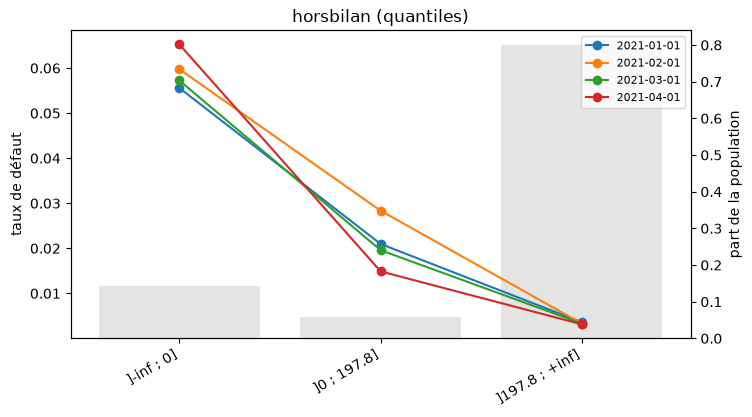

In [7]:
# Cellule 7 — revue graphique d'une variable (comparaison des 3 méthodes + règle retenue)
v = synthese_lisible["Variable"][0]
print(comparaison.filter(pl.col("variable") == v))
print(binning.table_regle(train, v, TARGET, regles[v]))
binning.graphique_regle(train, v, TARGET, DATE, regles[v]); plt.show()

## 1.6 Arrondi des bornes

Les bornes issues des méthodes automatiques ont des valeurs peu lisibles (par exemple 197,8 ou 0,9987). Pour obtenir une grille interprétable et actionnable (4.7), chaque borne est arrondie à deux chiffres significatifs (197,8 → 200 ; 0,9987 → 1). L'arrondi déplace légèrement les frontières de classes : il n'est conservé que si le découpage arrondi reste stable chaque mois (risque et volume), garde l'ordre des classes sur le test et perd moins de 5 % d'IV. Sinon, les bornes d'origine sont gardées. Le tableau ci-dessous détaille, variable par variable, les bornes avant / après et la décision.

**Résultat.** Sur les 31 variables numériques dont les bornes peuvent être arrondies, l'arrondi est retenu pour 26 sans perte notable d'IV (par exemple `solde_crediteur` : 1 600 / 5 500 / 30 000 ; `TX_UTIL_DAV` : 1 / 3,7 / 19). Il est refusé pour 5 variables. Pour `horsbilan`, `engagement` et `engagement_DAV`, une forte proportion de clients a exactement 200 € (montant standard d'autorisation de découvert) : la borne 199,9 sépare en réalité « moins de 200 € » et « 200 € et plus », et l'arrondir à 200 ferait basculer cette population, avec une chute d'IV de 1,76 à 1,54 pour `horsbilan`. Le cas est le même pour `PART_EPARGNE_DANS_AVOIRS` (clients à 100 % d'épargne). Pour `NBJ_ARR_MAX_13_48M`, l'arrondi rendait le découpage instable sur un mois. Les bornes d'origine sont alors conservées : elles se lisent directement (« moins de 200 € »). La stabilité en volume est vérifiée pour toutes les variables (PSI mensuel maximal de 0,01, pour un seuil de 0,1).

In [8]:
# Cellule 8 — arrondi des bornes (lisibilité, 4.7), conservé seulement s'il ne dégrade pas le découpage
regles, synthese, bilan_arrondi = binning.arrondir_regles(train, test, regles, TARGET, DATE, ecart_min=PARAMS["ecart_min"])
print(bilan_arrondi["arrondi_retenu"].sum(), "arrondis retenus sur",
      bilan_arrondi.filter(pl.col("bornes_origine") != pl.col("bornes_arrondies")).height, "variables arrondissables")
bilan_arrondi.filter(pl.col("bornes_origine") != pl.col("bornes_arrondies"))

26 arrondis retenus sur 31 variables arrondissables


shape: (31, 7)
┌───────────────────────────────┬────────────────────────────────────────────────────────────┬────────────────────────────────┬─────────────────┬─────────────────┬────────────────┬────────────────┐
│ variable                      ┆ bornes_origine                                             ┆ bornes_arrondies               ┆ iv_test_origine ┆ iv_test_arrondi ┆ stable_arrondi ┆ arrondi_retenu │
╞═══════════════════════════════╪════════════════════════════════════════════════════════════╪════════════════════════════════╪═════════════════╪═════════════════╪════════════════╪════════════════╡
│ solde_crediteur               ┆ [0.0, 1595.0, 5470.0, 29974.0]                             ┆ [0.0, 1600.0, 5500.0, 30000.0] ┆ 1.729232        ┆ 1.73223         ┆ true           ┆ true           │
│ horsbilan                     ┆ [0.0, 197.75]                                              ┆ [0.0, 200.0]                   ┆ 1.754623        ┆ 1.536254        ┆ true           ┆ false       

## 1.7 Variables à IV élevée : contrôle de la fuite d'information

21 variables ont une IV test supérieure à 0,5, seuil « suspect » selon Siddiqi, dont 11 au-delà de 1. Parmi elles, les variables construites (`TX_UTIL_DAV`, `ARR_TENDANCE`, `NBJ_ARR_MAX_12M`, `NBJ_ARR_MAX_13_48M`, `NB_FENETRES_ARR`) dérivent de fenêtres antérieures à la date d'observation et sont exemptes de fuite par construction. Le contrôle porte donc sur les 16 variables brutes : `horsbilan`, `solde_crediteur`, `ARR_GDT`, `MINSOLDE_PAR`, `CRTAD_AG_NBJDE_BB`, `bilan`, `CRTAE_AG_SLDEPA`, `solde_debiteur`, `RATIO_SOLDE_MOYEN_SUR_EPARGNE`, `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB`, `NBJ_ARR_SS`, `SOLDE_EVOLUTION_T_vs_T4`, `CRTAD_AG_MVTAFF_IND_0010`, `anciennete_jour_sain_M0`, `engagement`, `CRTAD_IND_0042`.

[À compléter : vérification, d'après le dictionnaire des variables, que chacune est mesurée au plus tard à la date d'observation.]

Dans un score comportemental sur des clients équipés en crédit, les variables de fonctionnement du compte (soldes, jours débiteurs, arriérés) sont les risk drivers les plus puissants ; une IV élevée y est attendue. L'IV est du même ordre entre apprentissage et test, ce qui exclut un surapprentissage du découpage.

## 1.8 Redondances entre variables découpées (3.2)

Le contrôle de redondance du notebook 0b portait sur les variables brutes (Spearman). Une fois découpées en 2 à 5 classes, des variables distinctes peuvent devenir quasi identiques (même population isolée dans une classe). On mesure donc la liaison entre variables découpées par le V de Cramér, calculé sur l'apprentissage. Pour chaque paire au-dessus du seuil, on conserve la variable de plus forte IV test. Le tableau final donne, pour chaque variable, son découpage et son statut définitif.

In [9]:
# Cellule 9 — redondances entre variables découpées (V de Cramér) et sélection finale
toutes = binning.redondances_classes(train, regles, seuil=0)
print(toutes.select(pl.col("v_cramer").quantile(q).alias(f"q{int(q * 100)}") for q in (0.5, 0.9, 0.95, 0.99)))
print(toutes.head(25))

paires = toutes.filter(pl.col("v_cramer") >= SEUIL_CRAMER)
selection = binning.selection_non_redondante(synthese, paires)
synthese_finale = binning.presenter_synthese(synthese, selection)
VARS_MODELE = selection.filter(pl.col("statut") == "retenue")["variable"].to_list()
print(synthese_finale.group_by("Verdict").len().sort("len", descending=True))
print(len(VARS_MODELE), "variables pour la modélisation")
synthese_finale

shape: (1, 4)
┌──────────┬──────────┬──────────┬──────────┐
│ q50      ┆ q90      ┆ q95      ┆ q99      │
╞══════════╪══════════╪══════════╪══════════╡
│ 0.147362 ┆ 0.347179 ┆ 0.492165 ┆ 0.736627 │
└──────────┴──────────┴──────────┴──────────┘
shape: (25, 3)
┌─────────────────────────────────┬─────────────────────────────────┬──────────┐
│ var1                            ┆ var2                            ┆ v_cramer │
╞═════════════════════════════════╪═════════════════════════════════╪══════════╡
│ RATIO_LITIGES_vs_AVOIRS         ┆ RATIO_MOUV_AFF_SUR_EPARGNE      ┆ 1.0      │
│ PART_EPARGNE_DANS_AVOIRS        ┆ RATIO_LITIGES_vs_AVOIRS         ┆ 0.999968 │
│ PART_EPARGNE_DANS_AVOIRS        ┆ RATIO_MOUV_AFF_SUR_EPARGNE      ┆ 0.999968 │
│ RATIO_SOLDE_MOYEN_SUR_EPARGNE   ┆ RATIO_LITIGES_vs_AVOIRS         ┆ 0.931266 │
│ RATIO_SOLDE_MOYEN_SUR_EPARGNE   ┆ RATIO_MOUV_AFF_SUR_EPARGNE      ┆ 0.931266 │
│ engagement                      ┆ engagement_immo                 ┆ 0.856865 │
│ CRTAD_AG_N

shape: (46, 11)
┌──────────────────────────────┬──────────────────┬─────────┬──────────┬─────────┬───────────┬───────────────────┬────────────────┬───────────────┬─────────────────────┬──────────────────────────────┐
│ Variable                     ┆ Méthode          ┆ Classes ┆ IV train ┆ IV test ┆ Gini test ┆ Pouvoir (Siddiqi) ┆ PSI max / mois ┆ Stable / mois ┆ Ordre conservé test ┆ Verdict                      │
╞══════════════════════════════╪══════════════════╪═════════╪══════════╪═════════╪═══════════╪═══════════════════╪════════════════╪═══════════════╪═════════════════════╪══════════════════════════════╡
│ horsbilan                    ┆ Quantiles        ┆ 3       ┆ 1.69     ┆ 1.75    ┆ 0.63      ┆ suspect           ┆ 0.001          ┆ oui           ┆ oui                 ┆ retenue : IV élevée,         │
│                              ┆                  ┆         ┆          ┆         ┆           ┆                   ┆                ┆               ┆                     ┆ vérifier l

### Résultats

La distribution des V de Cramér entre variables découpées est concentrée sur des liaisons faibles (médiane 0,15 ; 95e centile 0,49). Le seuil de 0,7 correspond environ au 99e centile : seules les liaisons très fortes sont traitées ici. Les liaisons modérées (0,5 à 0,7), par exemple entre `NBJ_ARR_MAX_12M` et `ARR_TENDANCE` ou entre `anciennete_jour_sain_M0` et `ANCIENNETE_modif`, sont conservées à ce stade et seront arbitrées lors de la sélection du modèle (VIF, significativité, chapitre 5).

Sept variables sont écartées pour redondance ; la variable conservée est celle de plus forte IV test :

| Variable écartée | Conservée à sa place | V de Cramér | Interprétation |
|---|---|---|---|
| `engagement_immo` | `engagement` | 0,86 | l'engagement immobilier est une composante de l'engagement total |
| `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB` | `CRTAD_AG_NBJDE_BB` | 0,83 | deux mesures des jours débiteurs |
| `engagement_DAV` | `horsbilan` | 0,82 | le découvert autorisé est un engagement hors-bilan |
| `NB_FENETRES_ARR` | `ARR_TENDANCE` | 0,77 | deux synthèses du même historique d'arriérés |
| `SOLDE_PENTE_3T` | `SOLDE_PENTE_4T` | 0,72 | même tendance du solde, sur 3 ou 4 trimestres |
| `RATIO_LITIGES_vs_AVOIRS` | `CRTAE_AG_SLDEPA` | 0,71 | une fois découpées, les deux variables isolent la même population (absence d'épargne) |
| `RATIO_MOUV_AFF_SUR_EPARGNE` | `CRTAE_AG_SLDEPA` | 0,71 | idem |

`PART_EPARGNE_DANS_AVOIRS` présente un V de 1 avec les deux ratios d'épargne écartés, mais elle est conservée : elle compte 3 classes contre 2, et les classes des ratios se déduisent entièrement des siennes. Elle contient donc toute leur information, avec une modalité supplémentaire.

**Bilan du chapitre 4 pour le segment SB** : 54 variables candidates → 46 après feature engineering → 44 discriminantes après binning → **37 variables non redondantes** pour la modélisation.

## 1.9 Export

Les règles de découpage sont sauvegardées au format JSON, ce qui permettra de les appliquer telles quelles à l'échantillon Out-of-Time. La synthèse finale, le contrôle des valeurs impossibles, la comparaison des méthodes, les tables WOE/IV (apprentissage et test) et les redondances sont exportés dans `outputs/binning_SB.xlsx` pour le dossier de validation.

In [10]:
# Cellule 10 — export : règles (réutilisables sur l'OOT), synthèse, tables WOE, redondances
binning.sauver_regles(regles, f"outputs/scorecard/regles_{CODE}.json")
exploration.exporter_excel({
    f"{CODE}_Synthese_finale": synthese_finale,
    f"{CODE}_Valeurs_impossibles": impossibles,
    f"{CODE}_Arrondi_bornes": bilan_arrondi,
    f"{CODE}_Comparaison": comparaison,
    f"{CODE}_WOE_train": binning.tables_woe(train, regles, TARGET),
    f"{CODE}_WOE_test": binning.tables_woe(test, regles, TARGET),
    f"{CODE}_Redondances": toutes.filter(pl.col("v_cramer") >= 0.5),
    f"{CODE}_Selection": selection,
}, f"outputs/binning_{CODE}.xlsx")
print("export :", f"outputs/binning_{CODE}.xlsx", "|", f"outputs/scorecard/regles_{CODE}.json")

export : outputs/binning_SB.xlsx | outputs/scorecard/regles_SB.json
